In [1]:
!pip install pandas numpy matplotlib seaborn xlrd openpyxl scikit-learn sqlalchemy pymysql

Defaulting to user installation because normal site-packages is not writeable
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.2/9.2 MB 84.4 kB/s eta 0:00:0031m89.6 kB/s eta 0:00:03
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [scikit-learn]0m 5/6 [scikit-learn]n]]


In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

RAW_FILE = (
    PROJECT_DIR
    / "data"
    / "raw"
    / "default of credit card clients.xls"
)

print("Project directory:", PROJECT_DIR)
print("Dataset found:", RAW_FILE.exists())

Project directory: /home/yashdaemon/credit-card-risk-analysis
Dataset found: True


In [3]:
df = pd.read_excel(RAW_FILE, header=1)

df.columns = (
    df.columns.astype(str)
    .str.strip()
    .str.lower()
    .str.replace(r"[^a-z0-9]+", "_", regex=True)
    .str.strip("_")
)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

display(df.head())

Dataset loaded successfully.
Rows: 30000
Columns: 25


,id,limit_bal,sex,education,marriage,age,pay_0,pay_2,pay_3,pay_4,...,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default_payment_next_month
0,1,20000,2,2,1,24,2,2,-1,-1,...,0,0,0,0,689,0,0,0,0,1
1,2,120000,2,2,2,26,-1,2,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,3,90000,2,2,2,34,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,4,50000,2,2,1,37,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,5,50000,1,2,1,57,-1,0,-1,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


In [4]:
print("Column names:")
print(df.columns.tolist())

print("\nData types:")
display(df.dtypes.to_frame("data_type"))

Column names:
['id', 'limit_bal', 'sex', 'education', 'marriage', 'age', 'pay_0', 'pay_2', 'pay_3', 'pay_4', 'pay_5', 'pay_6', 'bill_amt1', 'bill_amt2', 'bill_amt3', 'bill_amt4', 'bill_amt5', 'bill_amt6', 'pay_amt1', 'pay_amt2', 'pay_amt3', 'pay_amt4', 'pay_amt5', 'pay_amt6', 'default_payment_next_month']

Data types:


,data_type
id,int64
limit_bal,int64
sex,int64
education,int64
marriage,int64
age,int64
pay_0,int64
pay_2,int64
pay_3,int64
pay_4,int64


In [5]:
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values by column:")
display(
    df.isna().sum()
      .sort_values(ascending=False)
      .to_frame("missing_count")
)

Missing values: 0
Duplicate rows: 0

Missing values by column:


,missing_count
id,0
limit_bal,0
sex,0
education,0
marriage,0
age,0
pay_0,0
pay_2,0
pay_3,0
pay_4,0


In [6]:
target = "default_payment_next_month"

print("Target exists:", target in df.columns)

if target in df.columns:
    display(
        df[target]
        .value_counts()
        .sort_index()
        .rename_axis("default_status")
        .to_frame("customer_count")
    )

    print(f"Default rate: {df[target].mean():.2%}")
else:
    print("Review the column names to identify the target.")

Target exists: True


,customer_count
default_status,
0,23364
1,6636


Default rate: 22.12%


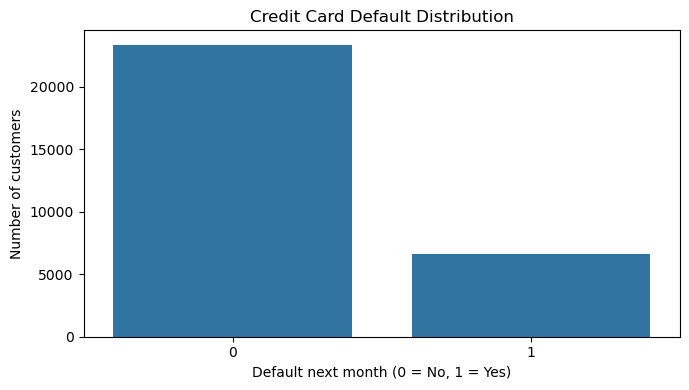

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(7, 4))

sns.countplot(
    data=df,
    x=target
)

plt.title("Credit Card Default Distribution")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

 Exploratory Data Analysis

In [8]:
eda_df = df.copy()

eda_df = eda_df.drop(columns=["id"], errors="ignore")

print("Target values:", sorted(eda_df[target].dropna().unique()))
print("Total customers:", len(eda_df))
print(f"Overall default rate: {eda_df[target].mean():.2%}")

Target values: [np.int64(0), np.int64(1)]
Total customers: 30000
Overall default rate: 22.12%


In [9]:
default_summary = (
    eda_df.groupby(target)
    .agg(
        customer_count=(target, "size"),
        avg_credit_limit=("limit_bal", "mean"),
        avg_age=("age", "mean"),
        avg_bill_amt_1=("bill_amt1", "mean"),
        avg_payment_amt_1=("pay_amt1", "mean")
    )
)

default_summary.index = [
    "No Default" if x == 0 else "Default"
    for x in default_summary.index
]

display(default_summary.round(2))

,customer_count,avg_credit_limit,avg_age,avg_bill_amt_1,avg_payment_amt_1
No Default,23364,178099.73,35.42,51994.23,6307.34
Default,6636,130109.66,35.73,48509.16,3397.04


,credit_limit_group,default_rate
0,Up to 50K,31.79
1,50K–100K,25.80
2,100K–200K,19.48
3,200K–500K,14.80
4,Above 500K,11.17


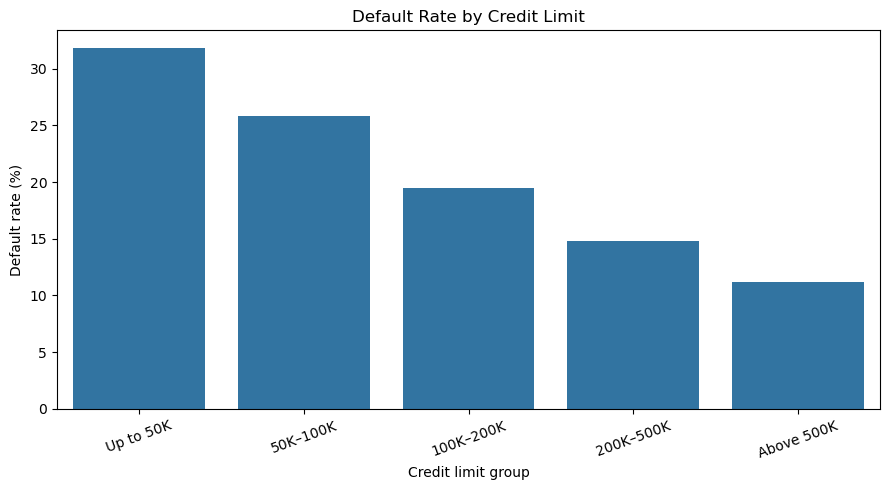

In [10]:
eda_df["credit_limit_group"] = pd.cut(
    eda_df["limit_bal"],
    bins=[-1, 50000, 100000, 200000, 500000, float("inf")],
    labels=[
        "Up to 50K",
        "50K–100K",
        "100K–200K",
        "200K–500K",
        "Above 500K"
    ]
)

limit_default = (
    eda_df.groupby("credit_limit_group", observed=False)[target]
    .mean()
    .mul(100)
    .rename("default_rate")
    .reset_index()
)

display(limit_default.round(2))

plt.figure(figsize=(9, 5))
sns.barplot(
    data=limit_default,
    x="credit_limit_group",
    y="default_rate"
)
plt.title("Default Rate by Credit Limit")
plt.xlabel("Credit limit group")
plt.ylabel("Default rate (%)")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

In [11]:
repayment_cols = [
    "pay_0", "pay_2", "pay_3",
    "pay_4", "pay_5", "pay_6"
]

repayment_summary = (
    eda_df.groupby(target)[repayment_cols]
    .mean()
    .T
    .rename(columns={0: "No Default", 1: "Default"})
)

display(repayment_summary.round(3))

default_payment_next_month,No Default,Default
pay_0,-0.211,0.668
pay_2,-0.302,0.458
pay_3,-0.316,0.362
pay_4,-0.356,0.255
pay_5,-0.389,0.168
pay_6,-0.406,0.112


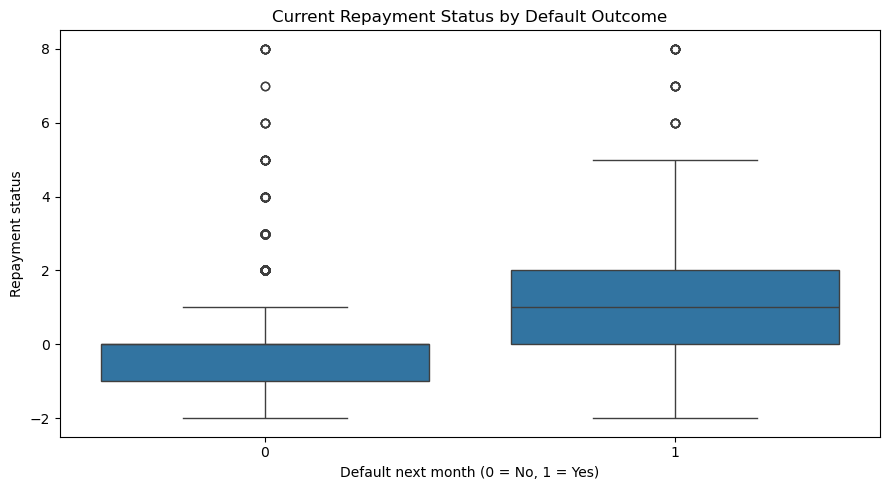

In [12]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=eda_df,
    x=target,
    y="pay_0"
)

plt.title("Current Repayment Status by Default Outcome")
plt.xlabel("Default next month (0 = No, 1 = Yes)")
plt.ylabel("Repayment status")
plt.tight_layout()
plt.show()

In [14]:
from pathlib import Path

PROJECT_DIR = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)

PROCESSED_DIR = PROJECT_DIR / "data" / "processed"
REPORTS_DIR = PROJECT_DIR / "reports"

PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Processed directory:", PROCESSED_DIR)
print("Reports directory:", REPORTS_DIR)

Processed directory: /home/yashdaemon/credit-card-risk-analysis/data/processed
Reports directory: /home/yashdaemon/credit-card-risk-analysis/reports


In [15]:
eda_df.to_csv(
    PROCESSED_DIR / "credit_card_eda_data.csv",
    index=False
)

default_summary.to_csv(
    REPORTS_DIR / "default_summary.csv"
)

limit_default.to_csv(
    REPORTS_DIR / "default_rate_by_credit_limit.csv",
    index=False
)

print("EDA outputs saved successfully.")

EDA outputs saved successfully.
